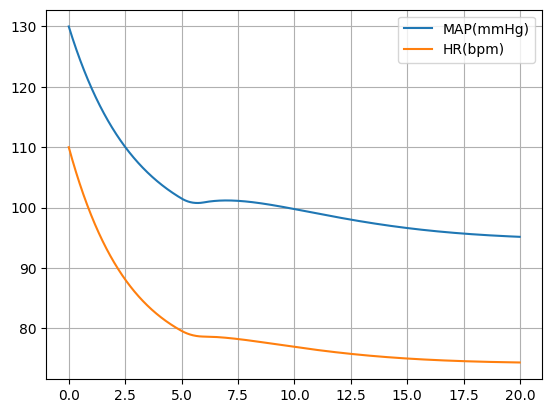

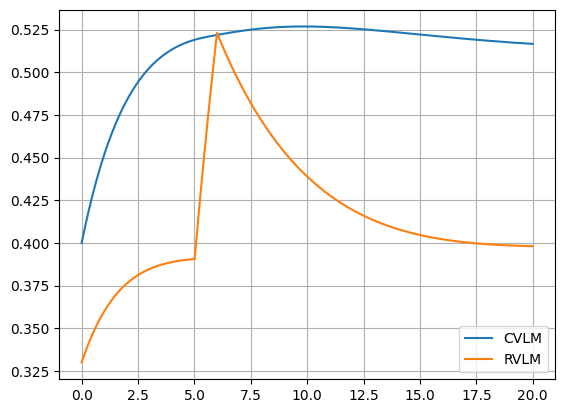

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 


dt = 0.01
τ1 = 3.2
τ2 = 4
τ3 = 3.4
τ4 = 3.1

κ1 = 1/92
κ2 = 1
κ4 = 0.78

a1 = 40
b1 = 40
a2 = 70
b2 = 10

Disturbance = 0

MAP_base = 90
HR_base = 72
RVLM_base = 0.8

V0 = 0.5
S0 = 0.33

def Σ(k, x):
    return 1 / (1 + np.exp(-(k*x)))

T = np.arange(0, 20, dt)
NTS = np.zeros_like(T)
CVLM = np.zeros_like(T)
RVLM = np.zeros_like(T)
MAP = np.zeros_like(T)
HR = np.zeros_like(T)

HR[0] = 110
MAP[0] = 130
CVLM[0] = 0.4
RVLM[0] = 0.33

for i in range(len(T)-1):
    NTS[i] = Σ(κ1, MAP[i] - MAP_base)

    CVLM_target = κ2 * NTS[i]
    dCVLM = (CVLM_target - CVLM[i]) / τ1
    CVLM[i+1] = CVLM[i] + dt * dCVLM
    CVLM[i+1] = min(1, max(0, CVLM[i+1]))

    if (T[i] > 5) & (T[i] < 6):
        Disturbance = 0.6
    else:
        Disturbance = 0

    RVLM_target = RVLM_base - κ4 * CVLM[i+1] + Disturbance
    RVLM_target = min(1, max(0, RVLM_target))
    dRVLM = (RVLM_target - RVLM[i]) / τ2
    RVLM[i+1] = RVLM[i] + dt * dRVLM
    RVLM[i+1] = min(1, max(0, RVLM[i+1]))



    S = RVLM[i+1]
    V = NTS[i]

    MAP_target = MAP_base + a2 * (S-S0) - b2 * (V-V0) 
    dMAP = (MAP_target - MAP[i]) / τ3
    MAP[i+1] = MAP[i] + dt * dMAP

    HR_target = HR_base + a1 * (S-S0) - b1 * (V-V0) 
    dHR = (HR_target - HR[i]) / τ4
    HR[i+1] = HR[i] + dt * dHR

    

plt.figure()
plt.plot(T, MAP, label = 'MAP(mmHg)')
plt.plot(T, HR, label = 'HR(bpm)')
plt.legend()
plt.grid()


plt.figure()
plt.plot(T, CVLM, label = 'CVLM')
plt.plot(T, RVLM, label = 'RVLM')
plt.legend()
plt.grid()

plt.show()
